# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import FMOWDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 360893


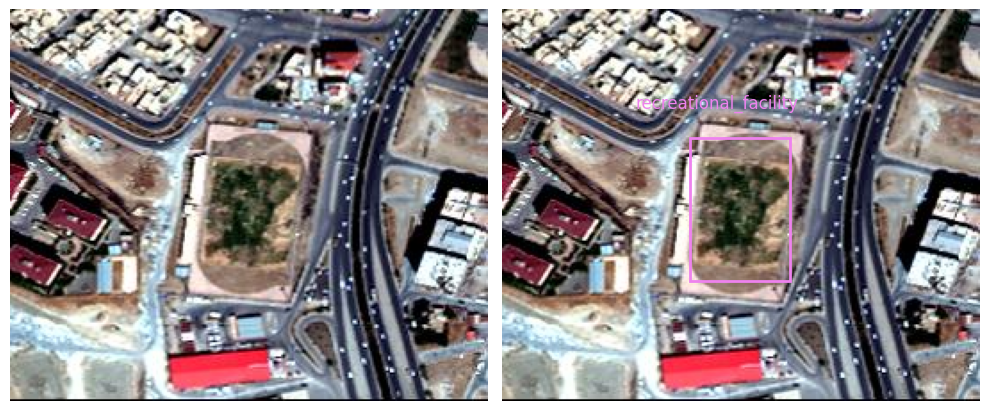

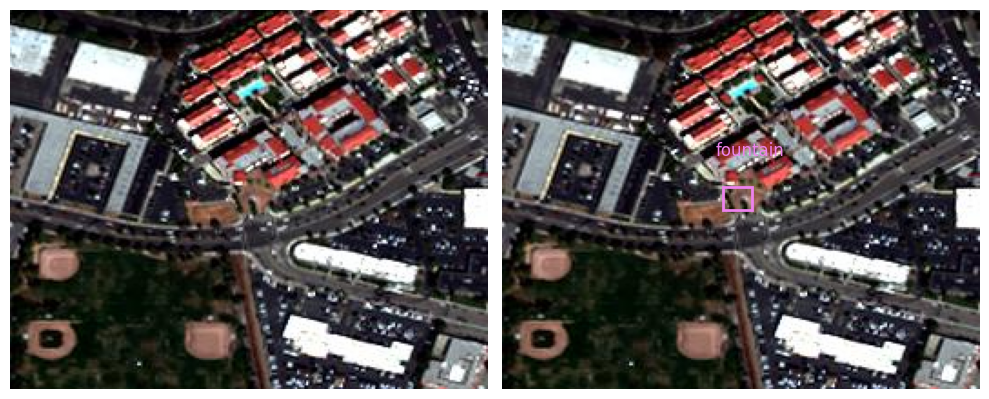

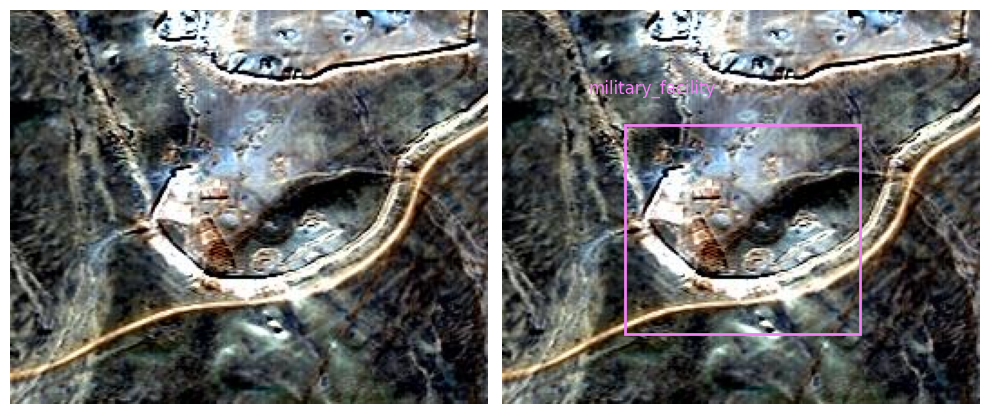

In [39]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/fMoW/train_new_structure/images_msrgb/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/fMoW/train_new_structure/annotations_msrgb/",
}
dataset = FMOWDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(10)
dataset.show_image(50);
dataset.show_image(100);

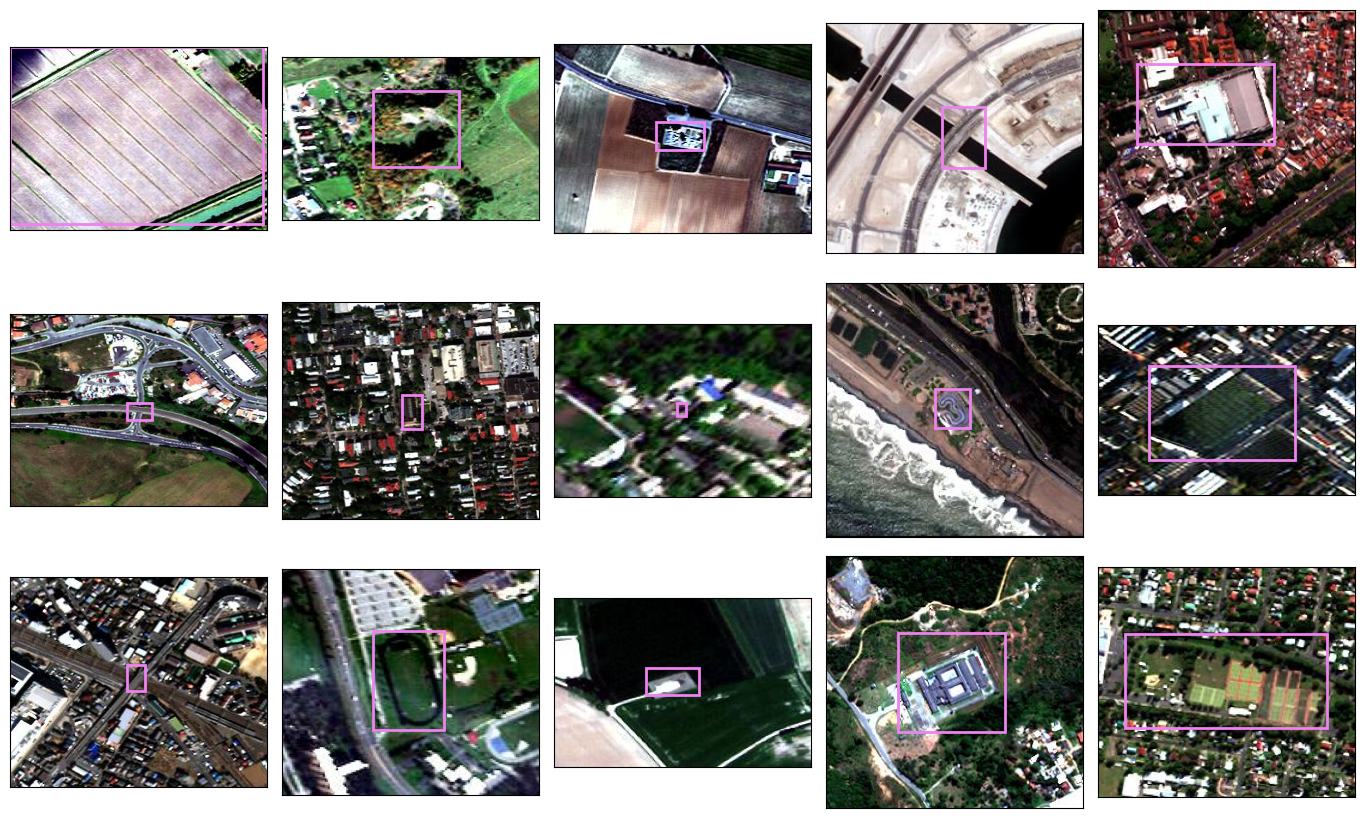

In [54]:
dataset.show_batch(15);

In [40]:
dataset.data_distribution_table()

,Label,Count
0,airport,1434
1,airport_hangar,4972
2,airport_terminal,4582
3,amusement_park,5888
4,aquaculture,1644
...,...,...
56,tunnel_opening,6330
57,waste_disposal,4301
58,water_treatment_facility,5517
59,wind_farm,5156


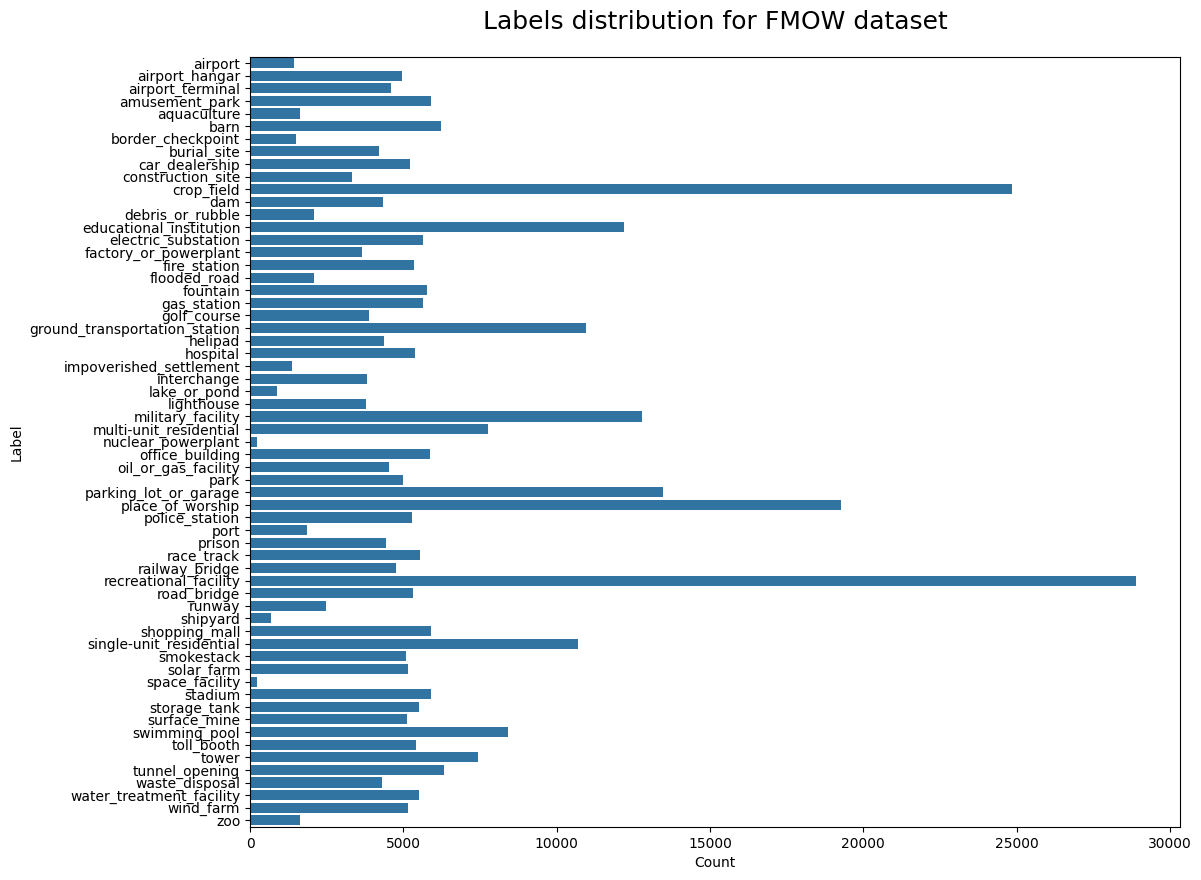

In [41]:
dataset.data_distribution_barchart();

## Load training data

In [5]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/fMoW/train_new_structure/images_msrgb/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/fMoW/train_new_structure/annotations_msrgb/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = FMOWDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 360893


## Create the model

In [6]:
epochs = 5
model_directory = "/home/dragik/data/FAIR_EO/experiments/fmow/"
model_config = {
    "num_classes": 61,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-07-28 07:46:11,406 INFO Starting training.
training: 100%|██████████| 22556/22556 [4:10:50<00:00,  1.50it/s]
2025-07-28 11:57:02,596 INFO epoch: 1, time: 15051, loss:  0.22737
testing on train set: 100%|██████████| 22556/22556 [2:16:12<00:00,  2.76it/s]  
2025-07-28 14:34:24,359 INFO map:0.12635256350040436, map_50:0.265268474817276, map_75:0.1088523343205452, map_small:0.014955723658204079, map_medium:0.06248849257826805, map_large:0.1419828236103058, mar_1:0.20172390341758728, mar_10:0.21629296243190765, mar_100:0.2163226157426834, mar_small:0.032620616257190704, mar_medium:0.1361335963010788, mar_large:0.22418542206287384, map_per_class:tensor(0.), tensor(0.4667), tensor(0.0011), tensor(0.2231), tensor(0.2520), tensor(0.0033), tensor(0.0023), tensor(0.1012), tensor(0.2404), tensor(0.1051), tensor(0.1045), tensor(0.1861), tensor(0.0064), tensor(0.2569), tensor(0.0919), tensor(0.0088), tensor(0.2741), tensor(0.0177), tensor(0.1479), tensor(0.5201), tensor(0.0665), tensor(0.0808),

## Predictions

2025-07-30 07:10:35,418 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/fmow/checkpoint.pth.tar
2025-07-30 07:10:35,720 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/fmow/checkpoint.pth.tar at epoch 6


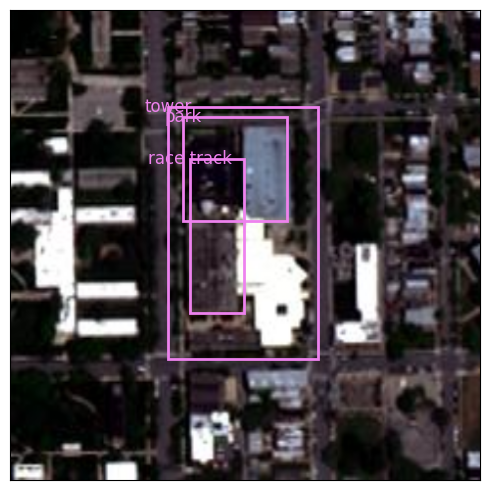

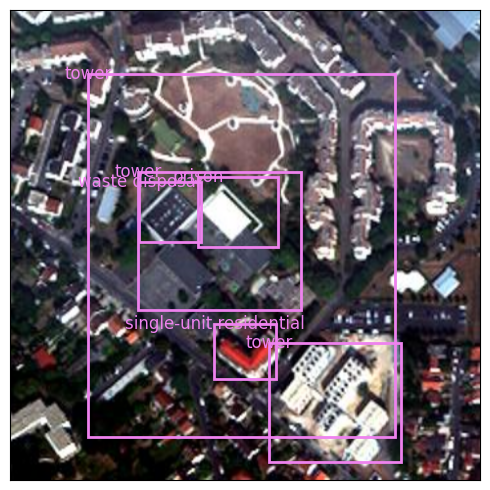

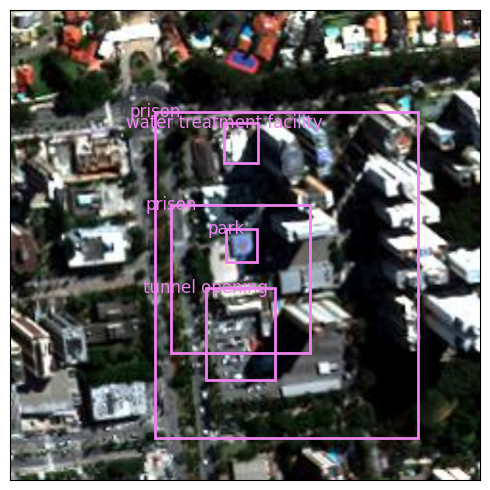

In [9]:
model_config = {
    "num_classes": 61,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/experiments/fmow/checkpoint.pth.tar"

labels = ["false detection","airport","airport hangar","airpot terminal","amusement park","aquaculture","archeological site",
"barn","border checkpoint","burial site","car dealership","construction site","crop field","dam","debris or rubble",
"educational institution","electric substation","factory or powerplant","fire station","flooded road","fountain",
"gas station","golf course","ground transportation station","helipad","hospital","impoverished settlement","interchange",
"lake or pond","lighthouse","military facility","multi-unit residential","nuclear powerplant","office building",
"oil or gas facility","park","parking lot or garage","place of worship","police station","port","prison","race track",
"railway bridge","recreational facility","road bridge","runway","shipyard","shopping mall","single-unit residential",
"smokestack","solar farm","space facility","stadium","storage tank","surface mine","swimming pool","toll booth",
"tower","tunnel opening","waste disposal","water treatment facility","wind farm","zoo"]

transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/fMoW/test_new_structure/images_msrgb/0000001_4_msrgb.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/fMoW/test_new_structure/images_msrgb/0000006_5_msrgb.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/fMoW/test_new_structure/images_msrgb/0000012_7_msrgb.jpg')
fig = model.detect_objects(image, labels, transform)